# Homework 8 - Beyond 1D visualizations

### Aryan Dhuru

In this homework, you will repeat the exploratory analysis from [class hands-on](../class) but with another dataset. And also provide your own observations of the data.

Feel free to choose your own dataset (like the one you are using for the final project), or to keep things simple, you can use the Cars dataset.

## Instructions

1. **Project Setup**:  
   - Set up your Python and Jupyter (or VSCode) environment.  
   - Clone or download the repository provided in class (refer to the class notes).

2. **Fill the cells**:
    - Fill in the cells with the code provided in the instructions.
    - You can use the provided code as a starting point and modify it as needed.
    - Make sure to run the code in each cell to see the output.
    - Also respond the markdown questions in the notebook where indicated.

3. **Documentation**:  
   - Comment your code and add markdown explanations for each part of your analysis.

4. **Submission**:  
   - Ensure your notebook is complete and all cells are executed without errors.
   - Save your notebook and export as either PDF or HTML. If the visualizations using altair are not being shown in the html, submit a separated version with altair html. Refer to: https://altair-viz.github.io/getting_started/starting.html#publishing-your-visualization (you can use the `chart.save('chart_file.html')` method).
   - Submit to Canvas.

Ok let's import the packages

In [2]:
# For Jupyter notebooks, use 'widget' backend for interactivity
%matplotlib widget

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
import seaborn as sns
# make text editable in Illustrator
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

# import altair
import altair as alt
alt.data_transformers.disable_max_rows()

from pandas.plotting import parallel_coordinates


Now it is time to load a dataset. You can choose your own dataset or use the Cars dataset. If you want to use the Cars dataset, you can load it using the following code:


In [3]:
# Load ../Datasets/tree_data.csv
df = pd.read_csv("tree_data.csv") # adjust the path as needed
df.head()

,No,Plot,Subplot,Species,Light_ISF,Light_Cat,Core,Soil,Adult,Sterile,...,AMF,EMF,Phenolics,Lignin,NSC,Census,Time,Event,Harvest,Alive
0,126,1,C,Acer saccharum,0.106,Med,2017,Prunus serotina,I,Non-Sterile,...,22.00,NaN,-0.56,13.86,12.15,4,14.0,1.0,NaN,NaN
1,11,1,C,Quercus alba,0.106,Med,2017,Quercus rubra,970,Non-Sterile,...,15.82,31.07,5.19,20.52,19.29,33,115.5,0.0,NaN,X
2,12,1,C,Quercus rubra,0.106,Med,2017,Prunus serotina,J,Non-Sterile,...,24.45,28.19,3.36,24.74,15.01,18,63.0,1.0,NaN,NaN
3,2823,7,D,Acer saccharum,0.080,Med,2016,Prunus serotina,J,Non-Sterile,...,22.23,NaN,-0.71,14.29,12.36,4,14.0,1.0,NaN,NaN
4,5679,14,A,Acer saccharum,0.060,Low,2017,Prunus serotina,689,Non-Sterile,...,21.15,NaN,-0.58,10.85,11.20,4,14.0,1.0,NaN,NaN


### 2D Scatter plot
Choose two numeric variables from the dataset and plot a scatterplot using either matplotlib, seaborn, or altair. 
- Ensure to include appropriate labels and a title for the plot.

Try to encode an additional categorical variable (if available) in the scatterplot using color. For instance, for the car dataset, you can use Make or Fuel Type

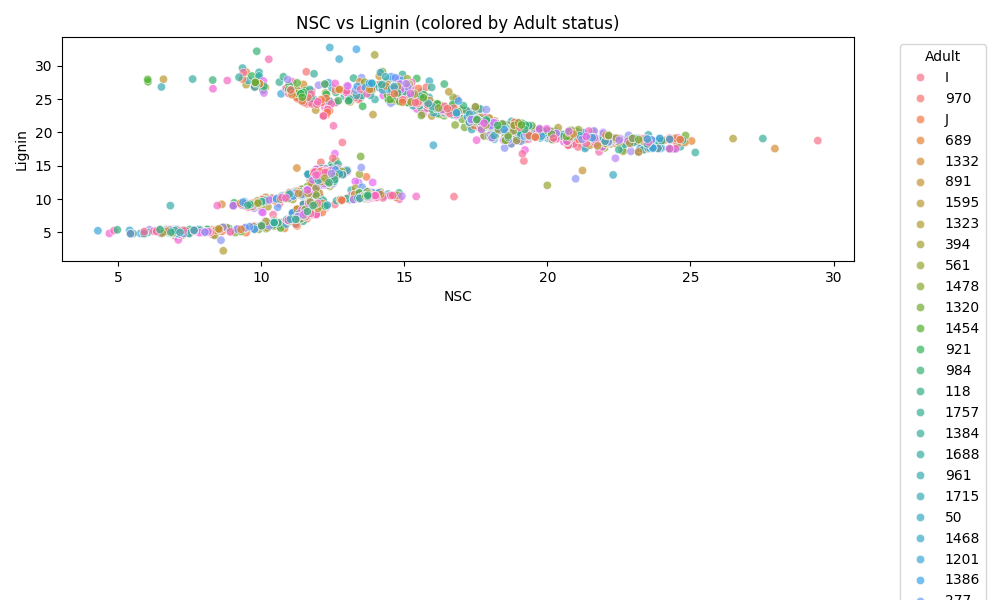

In [4]:
df2 = df.dropna(subset=['NSC', 'Lignin', 'Adult'])

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df2, x='NSC', y='Lignin', hue='Adult', alpha=0.7)
plt.title('NSC vs Lignin (colored by Adult status)')
plt.xlabel('NSC')
plt.ylabel('Lignin')
plt.legend(title='Adult', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


### 3D Scatter plot
Now choose three numeric variables from the dataset and plot a 3D scatterplot. You can use matplotlib's `mpl_toolkits.mplot3d` or any other library that supports 3D plotting.

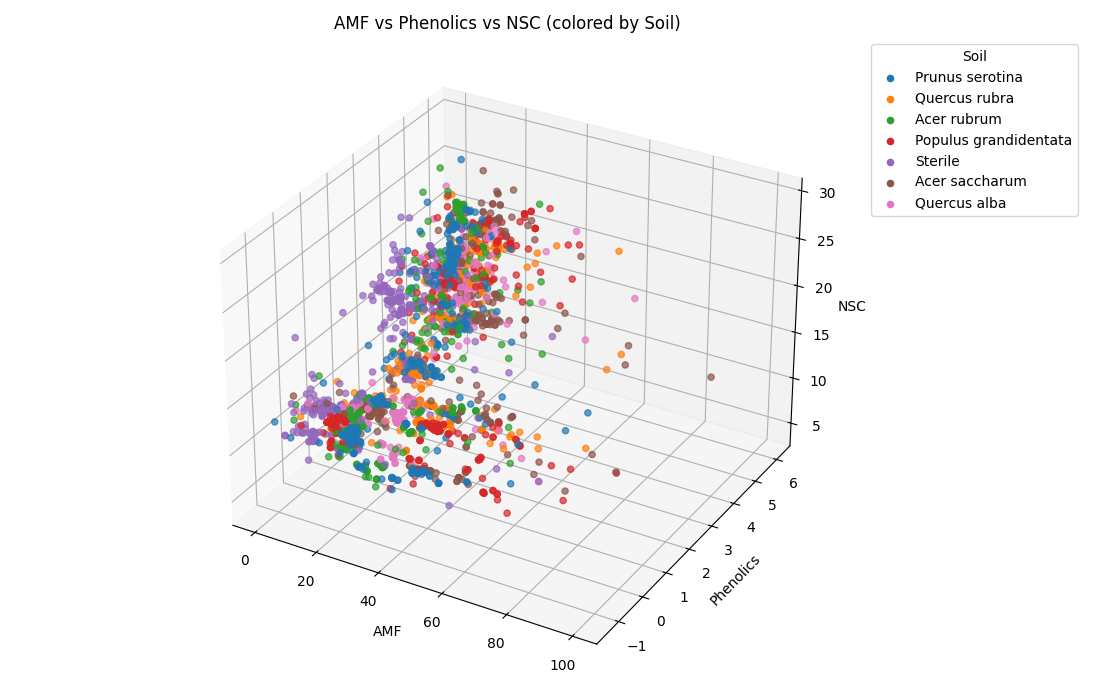

In [4]:
# YOUR CODE HERE
df3 = df.dropna(subset=['AMF', 'Phenolics', 'NSC', 'Soil'])
unique_soils = df3['Soil'].unique()
palette = sns.color_palette('tab10', len(unique_soils))
color_map = dict(zip(unique_soils, palette))
colors = df3['Soil'].map(color_map)

fig = plt.figure(figsize=(11, 7))
ax = fig.add_subplot(111, projection='3d')

sc = ax.scatter(df3['AMF'], df3['Phenolics'], df3['NSC'], c=colors, alpha=0.7)
ax.set_title('AMF vs Phenolics vs NSC (colored by Soil)')
ax.set_xlabel('AMF')
ax.set_ylabel('Phenolics')
ax.set_zlabel('NSC')

for label in unique_soils:
    ax.scatter([], [], [], color=color_map[label], label=label)
ax.legend(title='Soil', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()


### Find the numeric variables in the dataset
Now we will find all the numeric variables in the dataset. This will help us choose the variables for the further analysis.

In [ ]:
# list of numeric features (get from data)
numeric_features = df.select_dtypes(include=['float64', 'int64']).columns.tolist()
# remove No, core, census
numeric_features.remove('No')
numeric_features.remove('Core')
numeric_features.remove('Census')
numeric_features

['Plot',
 'Light_ISF',
 'AMF',
 'EMF',
 'Phenolics',
 'Lignin',
 'NSC',
 'Time',
 'Event']

### Correlation Matrix
For your selection of numeric variables, plot the correlation matrix using seaborn's `heatmap` or any other visualization library of your choice.

First Pearson, then Spearman correlation. Do you see any differences?

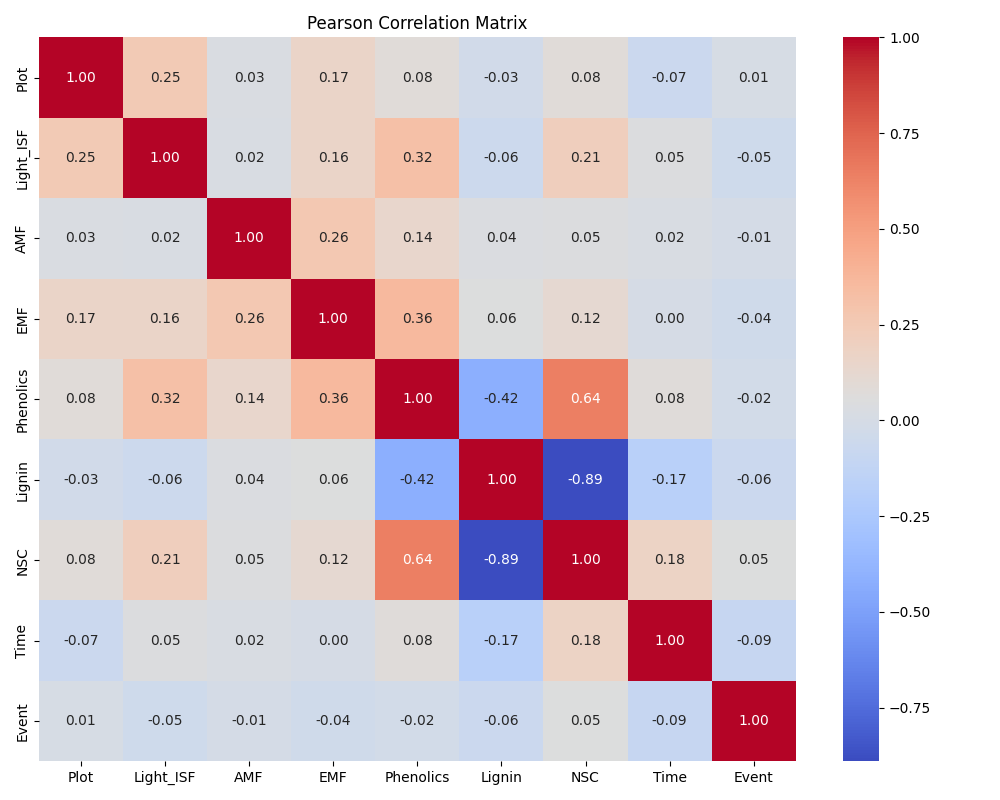

In [6]:
# Pearson correlation matrix
# YOUR CODE HERE
num_df = df[numeric_features].dropna()

plt.figure(figsize=(10, 8))
sns.heatmap(num_df.corr(method='pearson'), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Pearson Correlation Matrix')
plt.tight_layout()
plt.show()

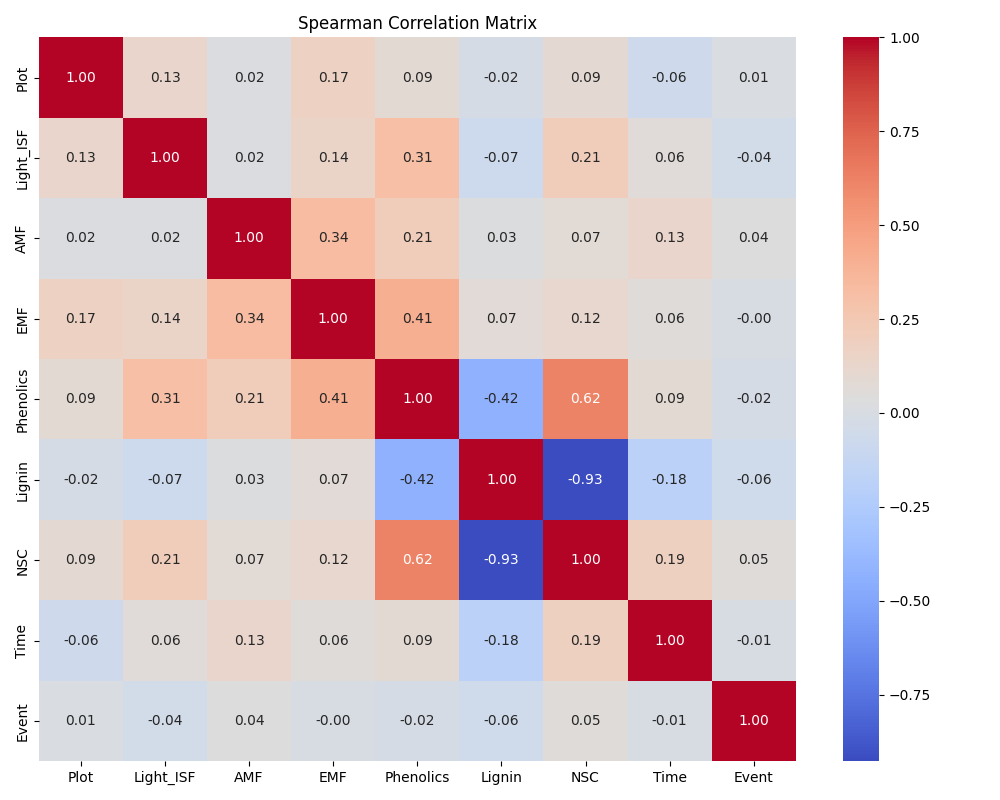

In [7]:
# Spearman correlation matrix
# YOUR CODE HERE
plt.figure(figsize=(10, 8))
sns.heatmap(num_df.corr(method='spearman'), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Spearman Correlation Matrix')
plt.tight_layout()
plt.show()


### Scatterplot matrix
To visualize the relationships between all numeric variables, create a scatterplot matrix (also known as a pair plot). You can use seaborn's `pairplot`.

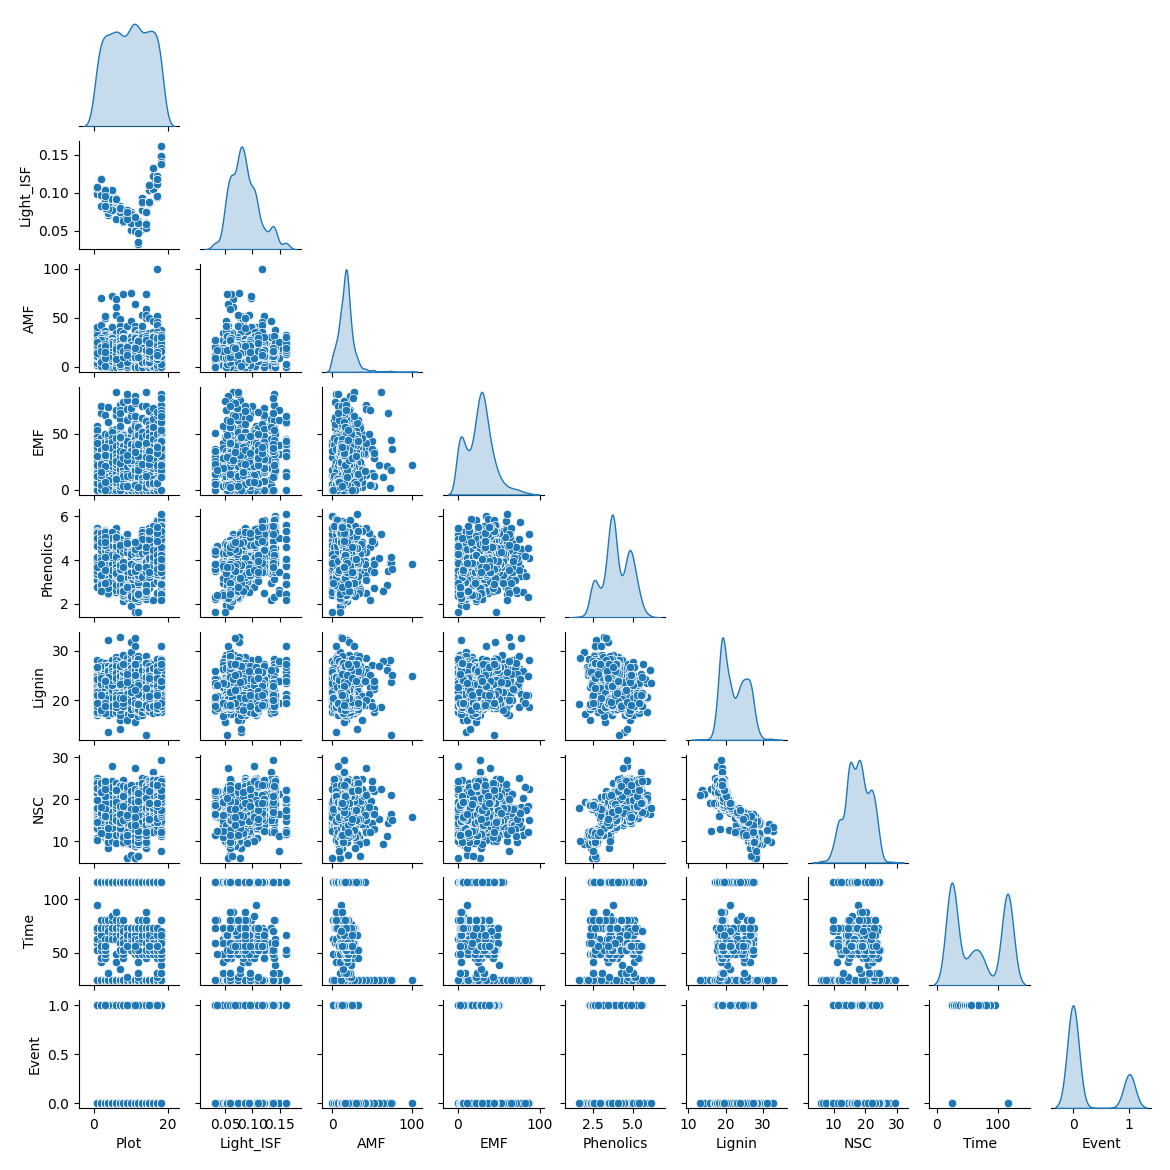

In [8]:
# YOUR CODE HERE

sns.pairplot(num_df, diag_kind='kde', corner=True, height=1.3, aspect=1)
plt.suptitle('Scatterplot Matrix of Numeric Variables', y=1.02)
plt.show()


### Parallel Coordinates Plot
Another way to visualize multi-dimensional data is by using a parallel coordinates plot. You can either use pandas or altair for this.

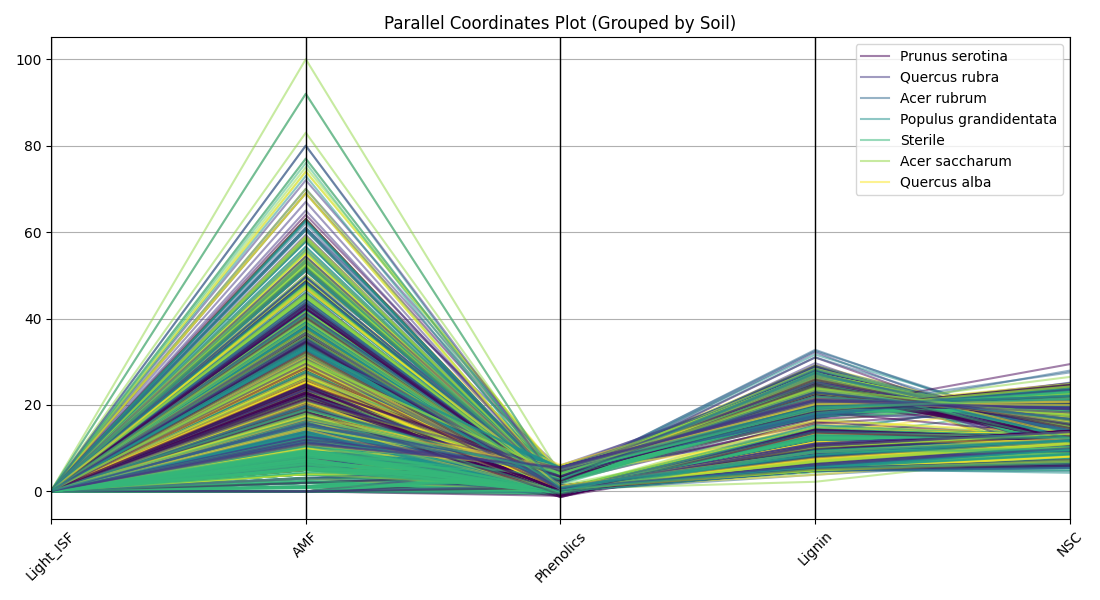

In [9]:
# YOUR CODE HERE
cols = ['Light_ISF', 'AMF', 'Phenolics', 'Lignin', 'NSC']
cat_col = 'Soil'

parallel_df = df[cols + [cat_col]].dropna()

plt.figure(figsize=(11, 6))
parallel_coordinates(parallel_df, class_column=cat_col, colormap='viridis', alpha=0.5)
plt.title('Parallel Coordinates Plot (Grouped by Soil)')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


### Discussion
Write a brief discussion on your observations from the visualizations above. Consider the following questions:
 - Did you gain any insights from the scatter plots (2D and 3D)?
 - Any interesting correlations you found in the correlation matrix?
 - Do you think the scatterplot matrix was helpful in understanding the relationships between variables? Was it too crowded or too sparse?
 - What about the parallel coordinates plot? Did it help in understanding the multi-dimensional relationships? Or was it too messy?



 `YOUR DISCUSSION HERE`

### Did you gain any insights from the scatter plots (2D and 3D)?

- The 2D scatter plot of NSC vs Lignin shows two distinct bands, suggesting subgroups in the data. However, Adult status doesn’t clearly separate these groups, indicating it may not be a strong influencing factor.
- The 3D plot (AMF vs Phenolics vs NSC) shows visible clustering based on soil type, especially along the AMF axis. This suggests soil type may significantly affect these variables.
- In summary, both plots help reveal trends and clustering that may not be obvious in 1D or tabular formats, with the 3D plot especially enriching our understanding of how multiple variables interact simultaneously.

### Any interesting correlations you found in the correlation matrix?

- Both correlation matrices highlight a strong negative correlation between Lignin and NSC (−0.89 Pearson, −0.93 Spearman), suggesting that as NSC increases, Lignin tends to decrease significantly.
- There’s also a moderate positive correlation between NSC and Phenolics (0.64 Pearson, 0.62 Spearman), indicating these two variables may rise together.
- Additionally, EMF and Phenolics show a moderate positive correlation, especially in the Spearman matrix (0.41), hinting at potential biological or environmental interactions.
- Overall, these matrices help identify which variables are strongly related and may be important for further analysis or modeling.

### Do you think the scatterplot matrix was helpful in understanding the relationships between variables? Was it too crowded or too sparse?

- The scatterplot matrix was helpful in visualizing pairwise relationships and spotting patterns, especially the strong negative trend between NSC and Lignin. 
- However, with many variables included, it did feel a bit crowded, making it harder to interpret some plots clearly.
- Reducing the number of variables or grouping related ones could improve clarity while retaining valuable insights.

### What about the parallel coordinates plot? Did it help in understanding the multi-dimensional relationships? Or was it too messy?

- The parallel coordinates plot was somewhat helpful in visualizing multidimensional relationships, especially for spotting trends across soil types.
- However, due to the dense overlapping lines, it was visually cluttered, making it hard to distinguish patterns for individual categories.
- Filtering or separating by soil type could improve clarity and make the insights more accessible.